In [2]:
import pandas as pd

url = "https://www.data.gouv.fr/api/1/datasets/r/bcd7d584-89c3-46b6-a164-4582eb2d43b5"
df = pd.read_csv(url, sep=";", encoding="utf-8")

print(df.shape)
df.head()

(3237, 8)


,librairie,assortiment,label,Commune,code_commune,Code_postal,Departement,Region
0,BLANCHE NEIGE,Généraliste,NaN,AMBERIEU EN BUGEY,01004,1500,AIN,AUVERGNE RHONE ALPES
1,ENTRE PARENTHESES,Généraliste,NaN,BELLEY,01034,1300,AIN,AUVERGNE RHONE ALPES
2,LIBRAIRIE ZANNINI,Généraliste,NaN,BOURG EN BRESSE,01053,1000,AIN,AUVERGNE RHONE ALPES
3,MONTBARBON,Généraliste,LIR,BOURG EN BRESSE,01053,1000,AIN,AUVERGNE RHONE ALPES
4,ZANNINI,Généraliste,NaN,BOURG EN BRESSE,01053,1000,AIN,AUVERGNE RHONE ALPES


In [3]:
df = df.rename(columns={"code_commune ": "code_commune"})

df = df[["librairie", "assortiment", "Commune", "code_commune"]].copy()

In [4]:
import requests

# Récupération de toutes les communes avec leur centroïde (lat/lon)
url_communes = (
    "https://geo.api.gouv.fr/communes"
    "?fields=code,nom,centre,codesPostaux"
    "&format=json"
    "&geometry=centre"
)

communes = requests.get(url_communes, timeout=60).json()
df_communes = pd.DataFrame(communes)

# Coordonnées depuis "centre.coordinates" -> [lon, lat]
df_communes["lon"] = df_communes["centre"].apply(
    lambda x: x.get("coordinates", [None, None])[0] if isinstance(x, dict) else None
)
df_communes["lat"] = df_communes["centre"].apply(
    lambda x: x.get("coordinates", [None, None])[1] if isinstance(x, dict) else None
)

df_communes = df_communes[["code", "nom", "lon", "lat"]].rename(
    columns={"code": "code_commune", "nom": "nom_commune_ref"}
)

# Merge sur code INSEE commune
df_map = df.merge(df_communes, on="code_commune", how="left")

print("Lignes:", len(df_map))
print("Coordonnées manquantes:", df_map[["lat", "lon"]].isna().any(axis=1).sum())
df_map.head()

Lignes: 3237
Coordonnées manquantes: 0


,librairie,assortiment,Commune,code_commune,nom_commune_ref,lon,lat
0,BLANCHE NEIGE,Généraliste,AMBERIEU EN BUGEY,01004,Ambérieu-en-Bugey,5.3706,45.9575
1,ENTRE PARENTHESES,Généraliste,BELLEY,01034,Belley,5.6927,45.7430
2,LIBRAIRIE ZANNINI,Généraliste,BOURG EN BRESSE,01053,Bourg-en-Bresse,5.2469,46.2027
3,MONTBARBON,Généraliste,BOURG EN BRESSE,01053,Bourg-en-Bresse,5.2469,46.2027
4,ZANNINI,Généraliste,BOURG EN BRESSE,01053,Bourg-en-Bresse,5.2469,46.2027


In [5]:
df_map.columns

Index(['librairie', 'assortiment', 'Commune', 'code_commune',
       'nom_commune_ref', 'lon', 'lat'],
      dtype='str')

In [6]:
nb_librairies = (
    df_map
    .groupby(["code_commune", "lon", "lat", "Commune"], as_index=False)
    .size()
    .rename(columns={"size": "nb_librairies"})
)

In [10]:
nb_librairies.head(10)

,code_commune,lon,lat,Commune,nb_librairies
0,01004,5.3706,45.9575,AMBERIEU EN BUGEY,1
1,01033,5.7944,46.1234,VALSERHONE,2
2,01034,5.6927,45.7430,BELLEY,1
3,01053,5.2469,46.2027,BOURG EN BRESSE,3
4,01093,4.9549,46.1264,CHATILLON SUR CHALARONNE,2
5,01143,6.1114,46.3754,DIVONNE LES BAINS,1
6,01160,6.1061,46.2520,FERNEY VOLTAIRE,2
7,01185,5.5775,45.9305,PLATEAU D HAUTEVILLE,1
8,01202,5.3396,45.8863,LAGNIEU,1
9,01244,5.2116,45.9047,MEXIMIEUX,1


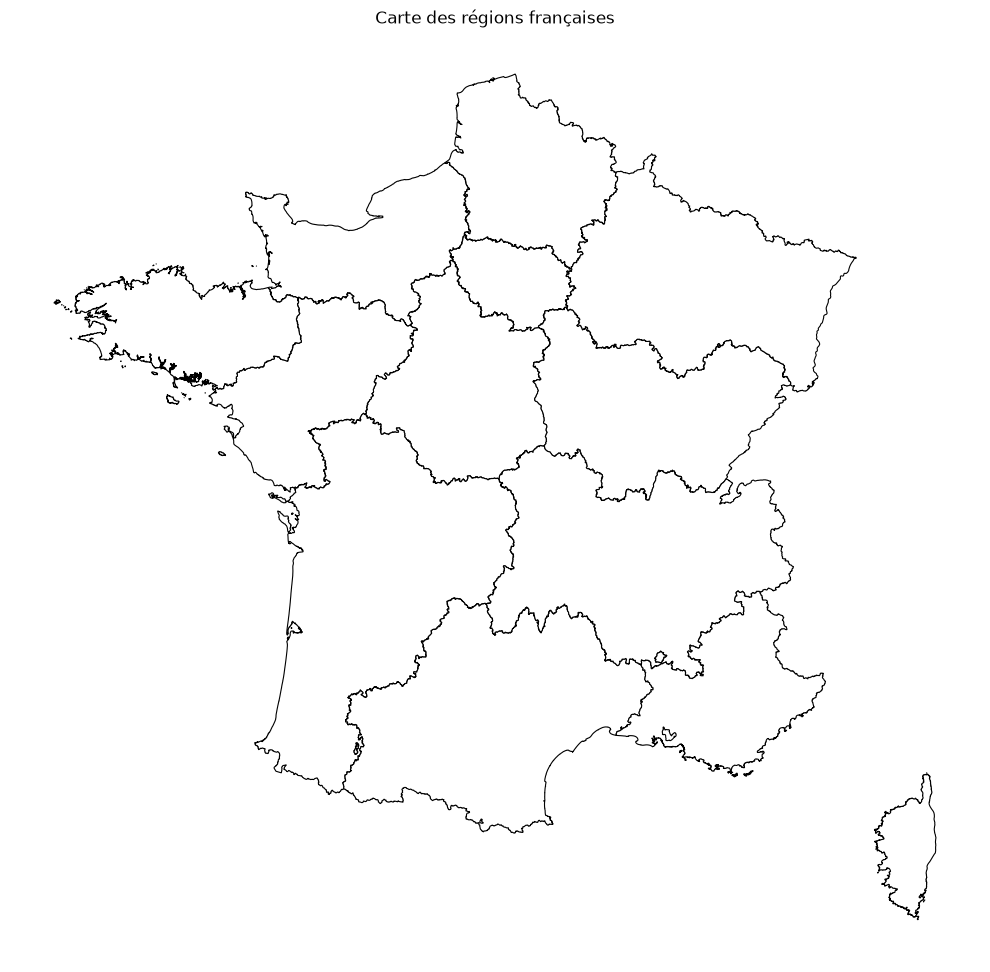

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

# URL du fichier GeoJSON des régions françaises
url = (
    "https://raw.githubusercontent.com/"
    "gregoiredavid/france-geojson/master/regions.geojson"
)

# Dossier de sauvegarde
dossier = Path("carte_france")
dossier.mkdir(exist_ok=True)

fichier = dossier / "regions.geojson"

# Télécharger le fond de carte
response = requests.get(url, timeout=30)
response.raise_for_status()
fichier.write_bytes(response.content)

# Charger les contours des régions
regions = gpd.read_file(fichier)

# Afficher une carte vierge avec les contours
fig, ax = plt.subplots(figsize=(10, 10))

regions.plot(
    ax=ax,
    facecolor="white",
    edgecolor="black",
    linewidth=0.8
)

ax.set_title("Carte des régions françaises")
ax.set_axis_off()

plt.tight_layout()

# Enregistrer la carte en haute résolution
plt.savefig(
    dossier / "fond_de_carte.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
nb_librairies_filtre = nb_librairies[
    nb_librairies["lon"].between(-5.5, 10) &
    nb_librairies["lat"].between(41, 51.5)
].copy()

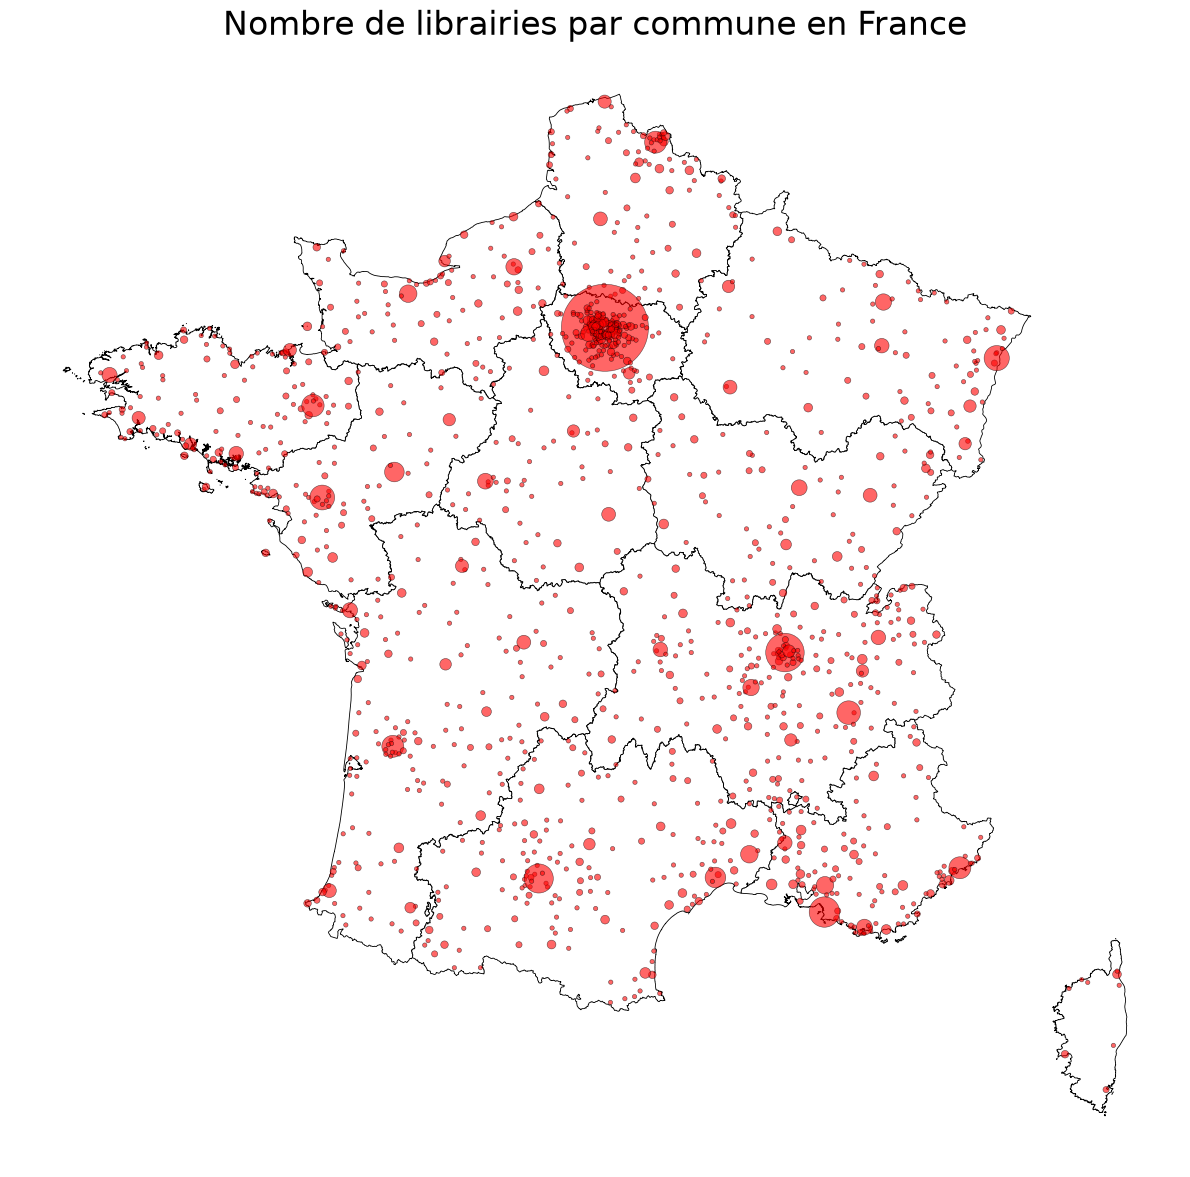

In [20]:
# Créer un GeoDataFrame à partir des coordonnées lon et lat
gdf_points = gpd.GeoDataFrame(
    nb_librairies_filtre,
    geometry=gpd.points_from_xy(nb_librairies_filtre["lon"], nb_librairies_filtre["lat"]),
    crs="EPSG:4326"
)

# Utiliser le même système de coordonnées que le fond de carte
gdf_points = gdf_points.to_crs(regions.crs)

# Tracer la carte
fig, ax = plt.subplots(figsize=(12, 12))

regions.plot(
    ax=ax,
    facecolor="white",
    edgecolor="black",
    linewidth=0.6
)

# Taille des cercles proportionnelle au nombre de librairies
gdf_points.plot(
    ax=ax,
    markersize=gdf_points["nb_librairies"] * 10,
    color="red",
    alpha=0.6,
    edgecolor="black",
    linewidth=0.4
)

ax.set_title("Nombre de librairies par commune en France", fontsize=24)
ax.set_axis_off()

plt.tight_layout()
plt.show()